# Does a Typhoon Grow Like a Population?
## Growth-Curve Models of Typhoon Champi (2026)

*Typhoons in an El Niño Year, Part 1 of 3*

**JP Maulion** · National Institute of Physics, University of the Philippines Diliman · October 2026

![License: MIT](https://img.shields.io/badge/License-MIT-blue.svg) ![Python 3.10+](https://img.shields.io/badge/python-3.10%2B-blue.svg) ![Data: JTWC best track](https://img.shields.io/badge/data-JTWC%20%2F%20IBTrACS-lightgrey.svg) ![Series: Part 1 of 3](https://img.shields.io/badge/series-Part%201%20of%203-orange.svg)

## TL;DR

Typhoon Champi did not grow along one S-curve. It grew in two stages, like bacteria that finish one food, pause, then switch to a second food and grow again: a surge to about 133 knots, three days of wobbling at that level, then a second surge to 160 knots. A two-stage growth curve beats every single S-curve by a decisive margin, while the three classic single curves (logistic, Gompertz, Richards) cannot be told apart. That margin rests on Champi's final 12-hour jump from 135 to 160 knots; take away its last reading and the two-stage curve still leads, but only narrowly. Champi also kept getting bigger after it peaked: its gale-force zone was widest a day after its strongest winds, about 1,000 km across. By the official track's wind radii, gale-force winds reached Taiwan's coast for about two days, from the afternoon of 22 October to the afternoon of 24 October, Taiwan time.

*All numbers come from the track file in `data/`, the U.S. Joint Typhoon Warning Center's working best track. Until the agencies finalize Champi's best track, every number here is provisional.*

## Executive Summary

Champi was named on 15 October 2026 near the Marshall Islands, crossed about 5,200 km of open Pacific in ten days, peaked at 160 knots (296 km/h) and 895 hPa on 20 October, and passed within about 50 km of northeast Taiwan before turning north on 24 October. This notebook follows that journey and asks one modeling question: **what shape did Champi's strengthening take?**

We fit four growth curves borrowed from biology to the storm's wind speed: the **logistic** (symmetric S), the **Gompertz** (lopsided S, fast early), the **Richards** (a logistic with an extra knob for lopsidedness), and a **two-stage logistic** (two S-curves stacked, the shape of bacteria growing on two sugars in turn). A standard score (AICc) picks the winner without rewarding extra knobs. The two-stage curve wins by a wide margin.

Two more questions round out the picture. **How big was Champi, and how did its size change?** The agency track records the radius of gale-force winds in each quadrant, the radius of the eyewall and the outer edge of the storm, so we can draw its footprint to scale. **When did its winds reach Taiwan?** Comparing the gale-force radius with the distance to Taiwan's coast gives a simple clock, which lines up with the window of Taiwan's land typhoon warning.

## Introduction

### Why Champi matters
Champi reached Category 5 strength over the open Pacific, passed just south of Guam as a super typhoon, and then brushed northeast Taiwan, where it killed one person, injured hundreds and grounded nearly a thousand flights in a day [16]. It formed during a strong El Niño, the kind of year in which typhoons tend to be born farther east and live longer [1], [2]. That makes it a clean case study for a three-part series on typhoons in an El Niño year.

### Why growth curves
Forecasters already think of a storm's strength as something that grows toward a ceiling. One operational intensity model used by the U.S. National Hurricane Center is built on a logistic growth equation [3], and a western Pacific version extends it to 7-day forecasts [4]. So the logistic curve is the natural baseline. What we did not find, in targeted searches, is a fair contest between the logistic and its cousins on a single storm, or any use of a two-stage (bi-logistic) growth curve for storm intensity. The closest idea comes from studies of eyewall replacement cycles, which describe intense hurricanes as intensifying, weakening and then reintensifying, often to their lifetime peak [21].

> **Tip: how to read storm strength.** Strength here means the *maximum sustained wind*: the fastest wind near the center, averaged over one minute, in knots (1 knot = 1.852 km/h). The categories on the news (Category 1 to 5, "super typhoon") are bands on that one number. Size is a separate question: a storm can be very strong and small, or weak and huge.

## Goal

**North Star question:** How did Champi grow from a tropical depression into a super typhoon, and which simple growth law describes that growth best?

Four plain questions follow from it:
1. **How fast did it grow, and where did it level off?**
2. **What kind of growth was it?** One smooth S-curve, or more than one stage?
3. **Did it fade slower than it grew**, as the average storm does?
4. **How big was it, when did its winds reach Taiwan, and how strong was it when it got there?**

## Methodology

1. **Trace the storm.** Map the track colored by strength, and animate it with the storm's gale-force zone and outer edge drawn to scale.
2. **Measure the journey.** Track length, days at each strength level, the largest 24-hour gain and loss, and closest approach to Taiwan's coast.
3. **Fit the strengthening phase** (genesis to peak) with four curves: logistic, Gompertz, Richards and a two-stage logistic. All start at the first observed wind. Fits use least squares from several starting guesses (`scipy.optimize.curve_fit`).
4. **Pick a winner fairly** with AICc, a score that rewards a close fit but charges for every extra parameter, and report Akaike weights, the share of evidence each model earns [5]. Then stress-test the winner by refitting without each position in turn.
5. **Fit the whole life** with one skewed bell curve and compare average rise and decay rates with Emanuel (2000) [6], for every reasonable end point of the decay window, not just one.
6. **Track the storm's size**: gale-force radius by quadrant, eyewall radius and outer edge, over time.
7. **Build a Taiwan clock**: at each position, compare the distance from Champi's center to Taiwan's nearest coast with the gale-force radius on the side facing Taiwan.
8. **Compare the peak with the arrival**: map Champi's last two days with distance from Taiwan's coast, and compare its peak with its strongest wind within 300 km of Taiwan and at its closest approach.

The equations appear in the Results, right after the picture they describe.

## Data

This notebook starts from **processed, analysis-ready files** in `data/`: one table of Champi's track and one file of coastlines. Both ship with the repository, so the notebook runs offline and needs no download. How the raw agency records became these files (reading the JTWC format, resolving duplicate lines, cross-checking against IBTrACS, cutting the coastlines down to the western Pacific) is the subject of a companion project, *Building Champi's Track File*, planned for December 2026.

| Item | Original source | File in this repository |
|---|---|---|
| Champi track, every 6 hours, 14 Oct 12:00 to 24 Oct 12:00 UTC | JTWC working best track ("b-deck") for storm 29W [14] | `data/champi_2026_track.csv` |
| Cross-check of the track | IBTrACS v04r01 ACTIVE file [7]: same positions and pressures through 22 Oct, winds within 2 kt | (used in the companion project) |
| Coastlines | Natural Earth 1:50m land [8] | `data/land_wpac.geojson` |

### Data dictionary: `data/champi_2026_track.csv`

One row per 6-hourly position, 41 rows, no gaps in time.

| Column | Type | Unit | Example (first row) | Meaning |
|---|---|---|---|---|
| `iso_time` | date-time | UTC | 2026-10-14 12:00:00 | Time of the position |
| `name` | text | | CHAMPI | Storm name |
| `season` | integer | year | 2026 | Typhoon season |
| `lat` | decimal | degrees north | 9.6 | Latitude of the storm's center |
| `lon` | decimal | degrees east | 161.2 | Longitude of the storm's center |
| `wind_kt` | integer | knots | 30 | Maximum 1-minute sustained wind near the center (JTWC estimate) |
| `pres_hpa` | integer | hPa | 1003 | Minimum central pressure; lower means a deeper storm |
| `poci_hpa` | integer | hPa | 1010 | Pressure of the outermost closed isobar, the storm's "edge" pressure |
| `roci_nm` | integer | nautical miles | 255 | Radius of the outermost closed isobar: roughly the edge of the whole storm |
| `rmw_nm` | integer | nautical miles | 35 | Radius of maximum winds: roughly the eyewall |
| `r34_ne_nm`, `r34_se_nm`, `r34_sw_nm`, `r34_nw_nm` | decimal | nautical miles | (blank) | How far gale-force winds (34 kt or more) reach in each quadrant. Blank when they did not reach that quadrant: all four while Champi was below 34 kt, and one or two quadrants in its first days as a tropical storm |
| `source` | text | | jtwc_bdeck_working_best_track | Which version of the track this is |

1 nautical mile = 1.852 km; 1 knot = 1.852 km/h.

**Columns added by the notebook** when it loads the file (`cu.load_track`): `days` (days since the first position), `wind_kmh`, `category` (0 = tropical depression up to 6 = Category 5), and every radius in km (`roci_km`, `rmw_km`, `r34_ne_km` and the other quadrants), plus the gale-force radius averaged over the quadrants it reached (`r34_mean_km`) and its narrowest and widest quadrant (`r34_min_km`, `r34_max_km`).

**`data/land_wpac.geojson`:** land outlines (polygons in longitude and latitude) for every coast that touches the western Pacific map, used to draw the maps and to measure distance to Taiwan's coast.

**Where the story starts.** Champi's disturbance was tracked from about 11 October, but the official record starts at 14 October 12:00 UTC, when it became a tropical depression. We start there, as every best track does. Including the earlier days would add a long flat stretch that changes which single S-curve looks best, so the start point matters and is stated here on purpose.

> **Tip: three ways to measure a storm's size.** *ROCI* is the radius of the outermost closed isobar, roughly the edge of the whole storm. *R34* is how far winds of 34 knots or more (gale force) reach, given for each quadrant (NE, SE, SW, NW) because storms are rarely round. *RMW* is the radius of maximum winds, roughly the eyewall. On a weather map, ROCI is the whole pinwheel, R34 is the dangerous part, RMW is the ring around the eye.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import champi_utils as cu

track = cu.load_track("data/champi_2026_track.csv")
land = cu.load_land("data/land_wpac.geojson")

print(cu.data_source_note(track))
print(f"{len(track)} positions, {track.iso_time.iloc[0]:%d %b %H:%M} to {track.iso_time.iloc[-1]:%d %b %H:%M} UTC")
steps = sorted(set(track.iso_time.diff().dropna().dt.total_seconds() / 3600))
print("Hours between positions:", ", ".join(f"{h:g}" for h in steps))
track.head()

JTWC working best track (b-deck), provisional: 6-hourly positions with storm size. Agencies finalize the best track months later.
41 positions, 14 Oct 12:00 to 24 Oct 12:00 UTC
Hours between positions: 6


,iso_time,name,season,lat,lon,wind_kt,pres_hpa,poci_hpa,roci_nm,rmw_nm,r34_ne_nm,r34_se_nm,r34_sw_nm,r34_nw_nm,source,days,wind_kmh,category,roci_km,rmw_km,r34_ne_km,r34_se_km,r34_sw_km,r34_nw_km,r34_mean_km,r34_min_km,r34_max_km
0,2026-10-14 12:00:00,CHAMPI,2026,9.6,161.2,30,1003,1010,255,35,NaN,NaN,NaN,NaN,jtwc_bdeck_working_best_track,0.00,55.56,0,472.26,64.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-14 18:00:00,CHAMPI,2026,10.4,160.5,30,1004,1008,235,35,NaN,NaN,NaN,NaN,jtwc_bdeck_working_best_track,0.25,55.56,0,435.22,64.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-15 00:00:00,CHAMPI,2026,10.7,159.4,30,1004,1010,235,35,NaN,NaN,NaN,NaN,jtwc_bdeck_working_best_track,0.50,55.56,0,435.22,64.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-15 06:00:00,CHAMPI,2026,10.9,158.4,30,1002,1008,260,40,NaN,NaN,NaN,NaN,jtwc_bdeck_working_best_track,0.75,55.56,0,481.52,74.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-15 12:00:00,CHAMPI,2026,11.0,157.4,35,1001,1010,260,30,NaN,40.0,75.0,NaN,jtwc_bdeck_working_best_track,1.00,64.82,1,481.52,55.56,NaN,74.08,138.9,NaN,106.49,74.08,138.9


A quick check of the file before any analysis: how complete each column is, and its range. Only the gale-force radii have blanks, for the reason given in the dictionary.

In [2]:
raw_cols = ["lat", "lon", "wind_kt", "pres_hpa", "poci_hpa", "roci_nm", "rmw_nm",
            "r34_ne_nm", "r34_se_nm", "r34_sw_nm", "r34_nw_nm"]
check = pd.DataFrame({
    "non_blank": track[raw_cols].notna().sum(),
    "blank": track[raw_cols].isna().sum(),
    "min": track[raw_cols].min(),
    "max": track[raw_cols].max(),
})
display(check)

,non_blank,blank,min,max
lat,41,0,9.6,27.8
lon,41,0,122.3,161.2
wind_kt,41,0,30.0,160.0
pres_hpa,41,0,895.0,1004.0
poci_hpa,41,0,1004.0,1010.0
roci_nm,41,0,200.0,370.0
rmw_nm,41,0,5.0,40.0
r34_ne_nm,34,7,80.0,310.0
r34_se_nm,37,4,40.0,280.0
r34_sw_nm,37,4,65.0,220.0


## Results

### R1. The path

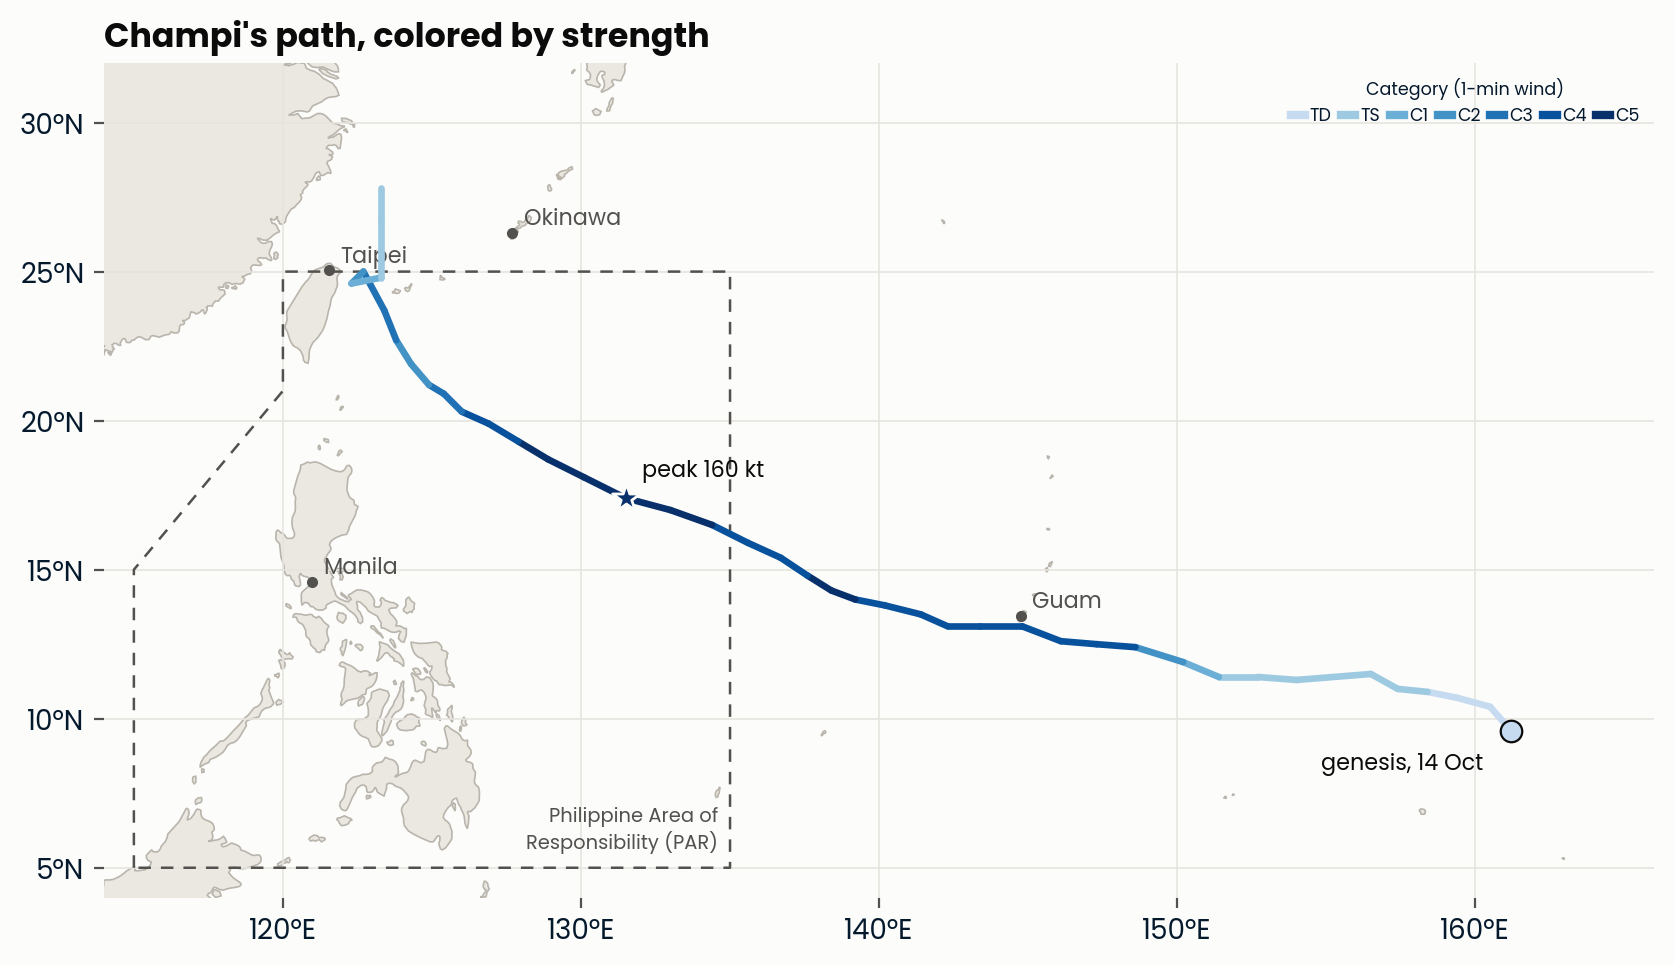

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.8))
cu.plot_track_map(track, land, ax=ax)
fig.savefig("figures/r1_track_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
gif_path = cu.make_gif(track, land, path="figures/champi_track.gif")
print("Animation saved to", gif_path)

Animation saved to figures/champi_track.gif


**Reading the path.** Champi formed deep in the tropics near the Marshall Islands and ran west-northwest in a nearly straight line, passing just south of Guam, then crossed into the Philippine Area of Responsibility (the dashed box, where PAGASA issues bulletins [15]) and bent north toward Taiwan. The darkest stretch of the line, where it was a Category 4 to 5 storm, sits over the open Philippine Sea, far from any coast. By the time it reached Taiwan it had already lost much of its strength.

Open `figures/champi_track.gif` to watch it move, one 6-hourly position at a time. The spiral is the standard weather-map symbol for a tropical cyclone, colored by category (open center below typhoon strength). The shaded shape around it is the gale-force zone drawn to scale, each quadrant at its own radius, and the dashed circle is the outer edge of the storm. The strips underneath show wind and pressure, with a line marking the current moment.

### R2. Strength over time

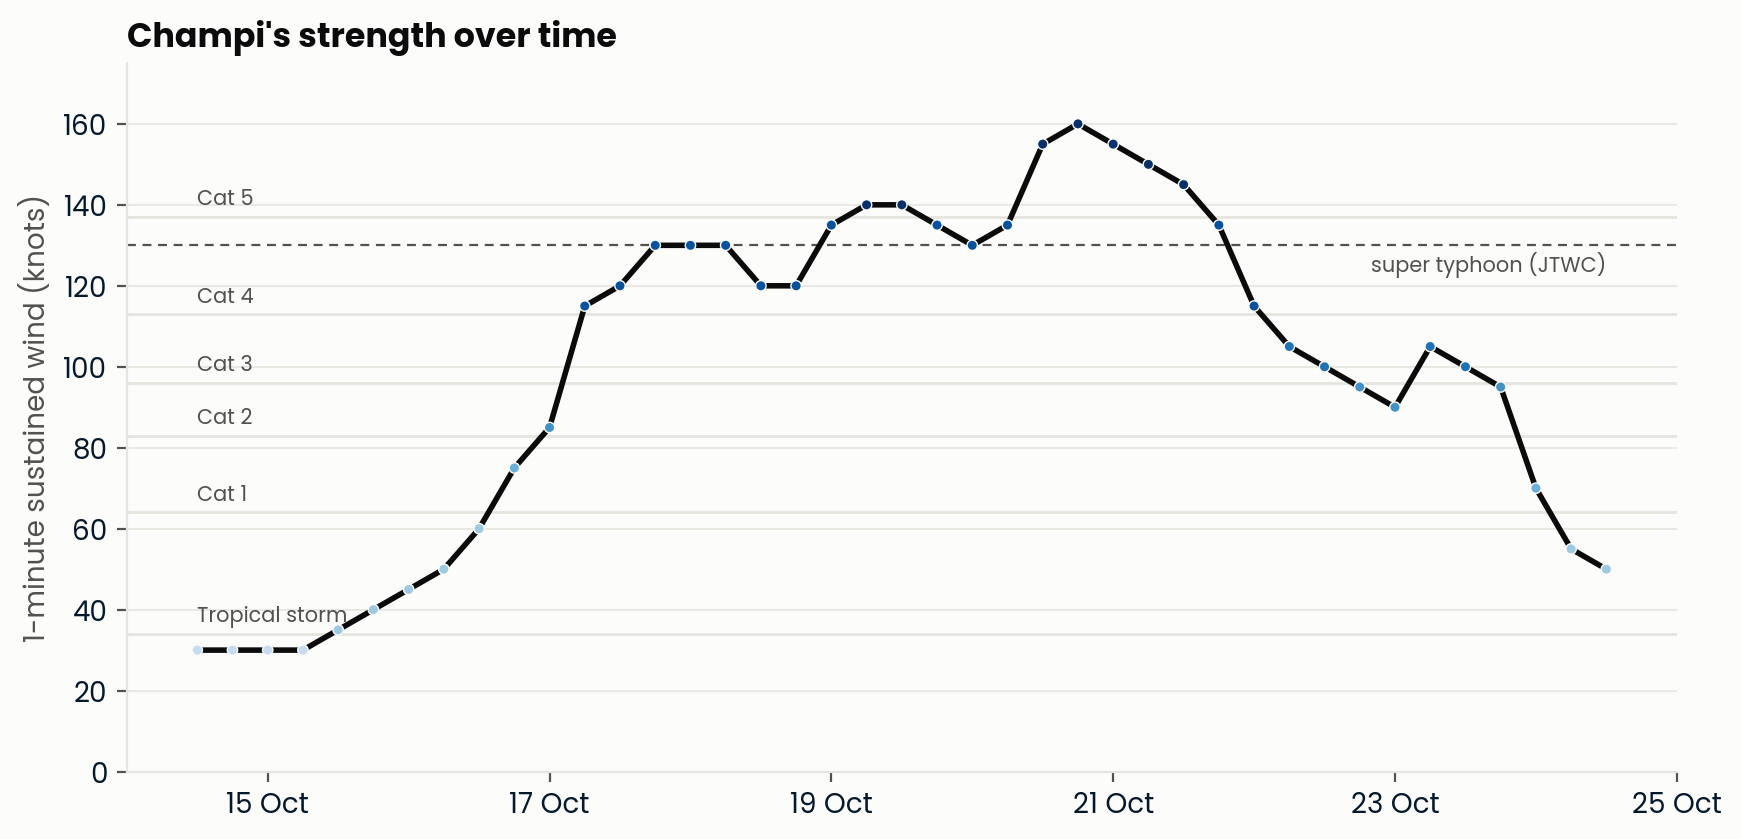

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
cu.plot_intensity(track, ax=ax)
fig.savefig("figures/r2_intensity.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the strength curve.** This is the line we model. It starts flat as a depression, then climbs steeply from tropical storm to Category 4 in under two days, the hallmark of rapid intensification. Then comes the part to watch: instead of topping out, it wobbles between 120 and 140 knots for nearly three days (often a sign of eyewall replacement cycles, which this data cannot confirm) and then surges again to 160 knots on 20 October. After the peak it falls, with one short rebound on 23 October just before it reached Taiwan.

### R3. The journey in numbers

In [6]:
runway = cu.runway_numbers(track, land)
runway.to_frame("Champi (2026)")

,Champi (2026)
First position (UTC),2026-10-14 12:00:00
"First position (lat, lon)","9.6N, 161.2E"
Last position (UTC),2026-10-24 12:00:00
Days tracked,10.0
Track length (km),5211
Straight-line distance (km),4448
Peak wind (kt),160
Peak wind (km/h),296
Lowest pressure (hPa),895
Peak time (UTC),2026-10-20 18:00:00


**Reading the numbers.** The track length is the distance Champi actually traveled; the straight-line distance is how far its last position is from its first. The days at each strength level and the largest 24-hour gain, set against the 30-knot rapid-intensification threshold [9], show that Champi did not just get strong, it stayed strong for days. The largest 24-hour loss came as it pulled away from Taiwan. Keep the track length in mind: Part 2 asks whether El Niño storms routinely get this kind of long runway.

### R4. Which growth law fits the strengthening?

The strengthening phase runs from genesis to the peak. Every curve starts at the first observed wind $L$; $K$ is the ceiling, $r$ sets how fast the climb is and $t_0$ when it happens.

| Model | Equation | Shape |
|---|---|---|
| Logistic | $V(t) = L + \dfrac{K-L}{1+e^{-r(t-t_0)}}$ | Symmetric S: speeds up and slows down at the same pace |
| Gompertz [10] | $V(t) = L + (K-L)\,e^{-e^{-r(t-t_0)}}$ | Lopsided S: fast early climb, long slow approach to the ceiling |
| Richards [11] | $V(t) = L + \dfrac{K-L}{\left(1+\nu e^{-r(t-t_0)}\right)^{1/\nu}}$ | Flexible S: $\nu = 1$ is the logistic, small $\nu$ approaches the Gompertz |
| Two-stage logistic [13] | $V(t) = L + \dfrac{K_1-L}{1+e^{-r_1(t-t_1)}} + \dfrac{D}{1+e^{-r_2(t-t_2)}}$ | Two S-curves stacked: a climb to a first plateau $K_1$, then a second climb of $D$ knots, so the final ceiling is $K_1 + D$ |

> **Tip: diauxic growth.** In the 1940s Jacques Monod grew bacteria on a mix of two sugars and saw two growth spurts with a pause between them: the cells used up the easy sugar, stalled while they switched, then grew again on the second [12]. Biologists call it *diauxic growth*, and the two-stage logistic is its simplest description. Economists use the same curve, the bi-logistic, for things that grow in two waves [13].

> **Tip: why not just pick the curve with the smallest error?** A curve with more knobs always fits at least as well, so raw error favors complexity. AICc adds a penalty per parameter. A difference of more than about 2 points is meaningful; more than 10 is decisive [5]. The two-stage curve has six parameters against three or four for the others, and AICc charges it for every one.

In [7]:
contest, curves, rise_data = cu.fit_rise(track)
for m in contest["model"]:
    print(f"{m:>20}: neighboring residuals correlate at {cu.residual_lag1(curves, rise_data, m):.2f}")
contest

  Two-stage logistic: neighboring residuals correlate at 0.34
            Logistic: neighboring residuals correlate at 0.54
            Gompertz: neighboring residuals correlate at 0.53
            Richards: neighboring residuals correlate at 0.53


,model,parameters,ceiling_kt,first_plateau_kt,growth_rate_per_day,midpoint_day,shape_nu,second_surge_day,second_surge_rate_per_day,fastest_growth_kt_per_day,rmse_kt,AICc,delta_AICc,akaike_weight
0,Two-stage logistic,6,160.1,133.0,2.599,2.32,NaN,5.91,16.21,109.8,4.87,102.50,0.00,0.998
1,Logistic,3,138.1,NaN,2.292,2.38,NaN,NaN,NaN,61.9,7.80,116.72,14.22,0.001
2,Gompertz,3,141.5,NaN,1.370,2.10,NaN,NaN,NaN,56.2,7.84,116.96,14.46,0.001
3,Richards,4,139.4,NaN,1.809,2.27,0.51,NaN,NaN,58.4,7.77,119.59,17.09,0.000


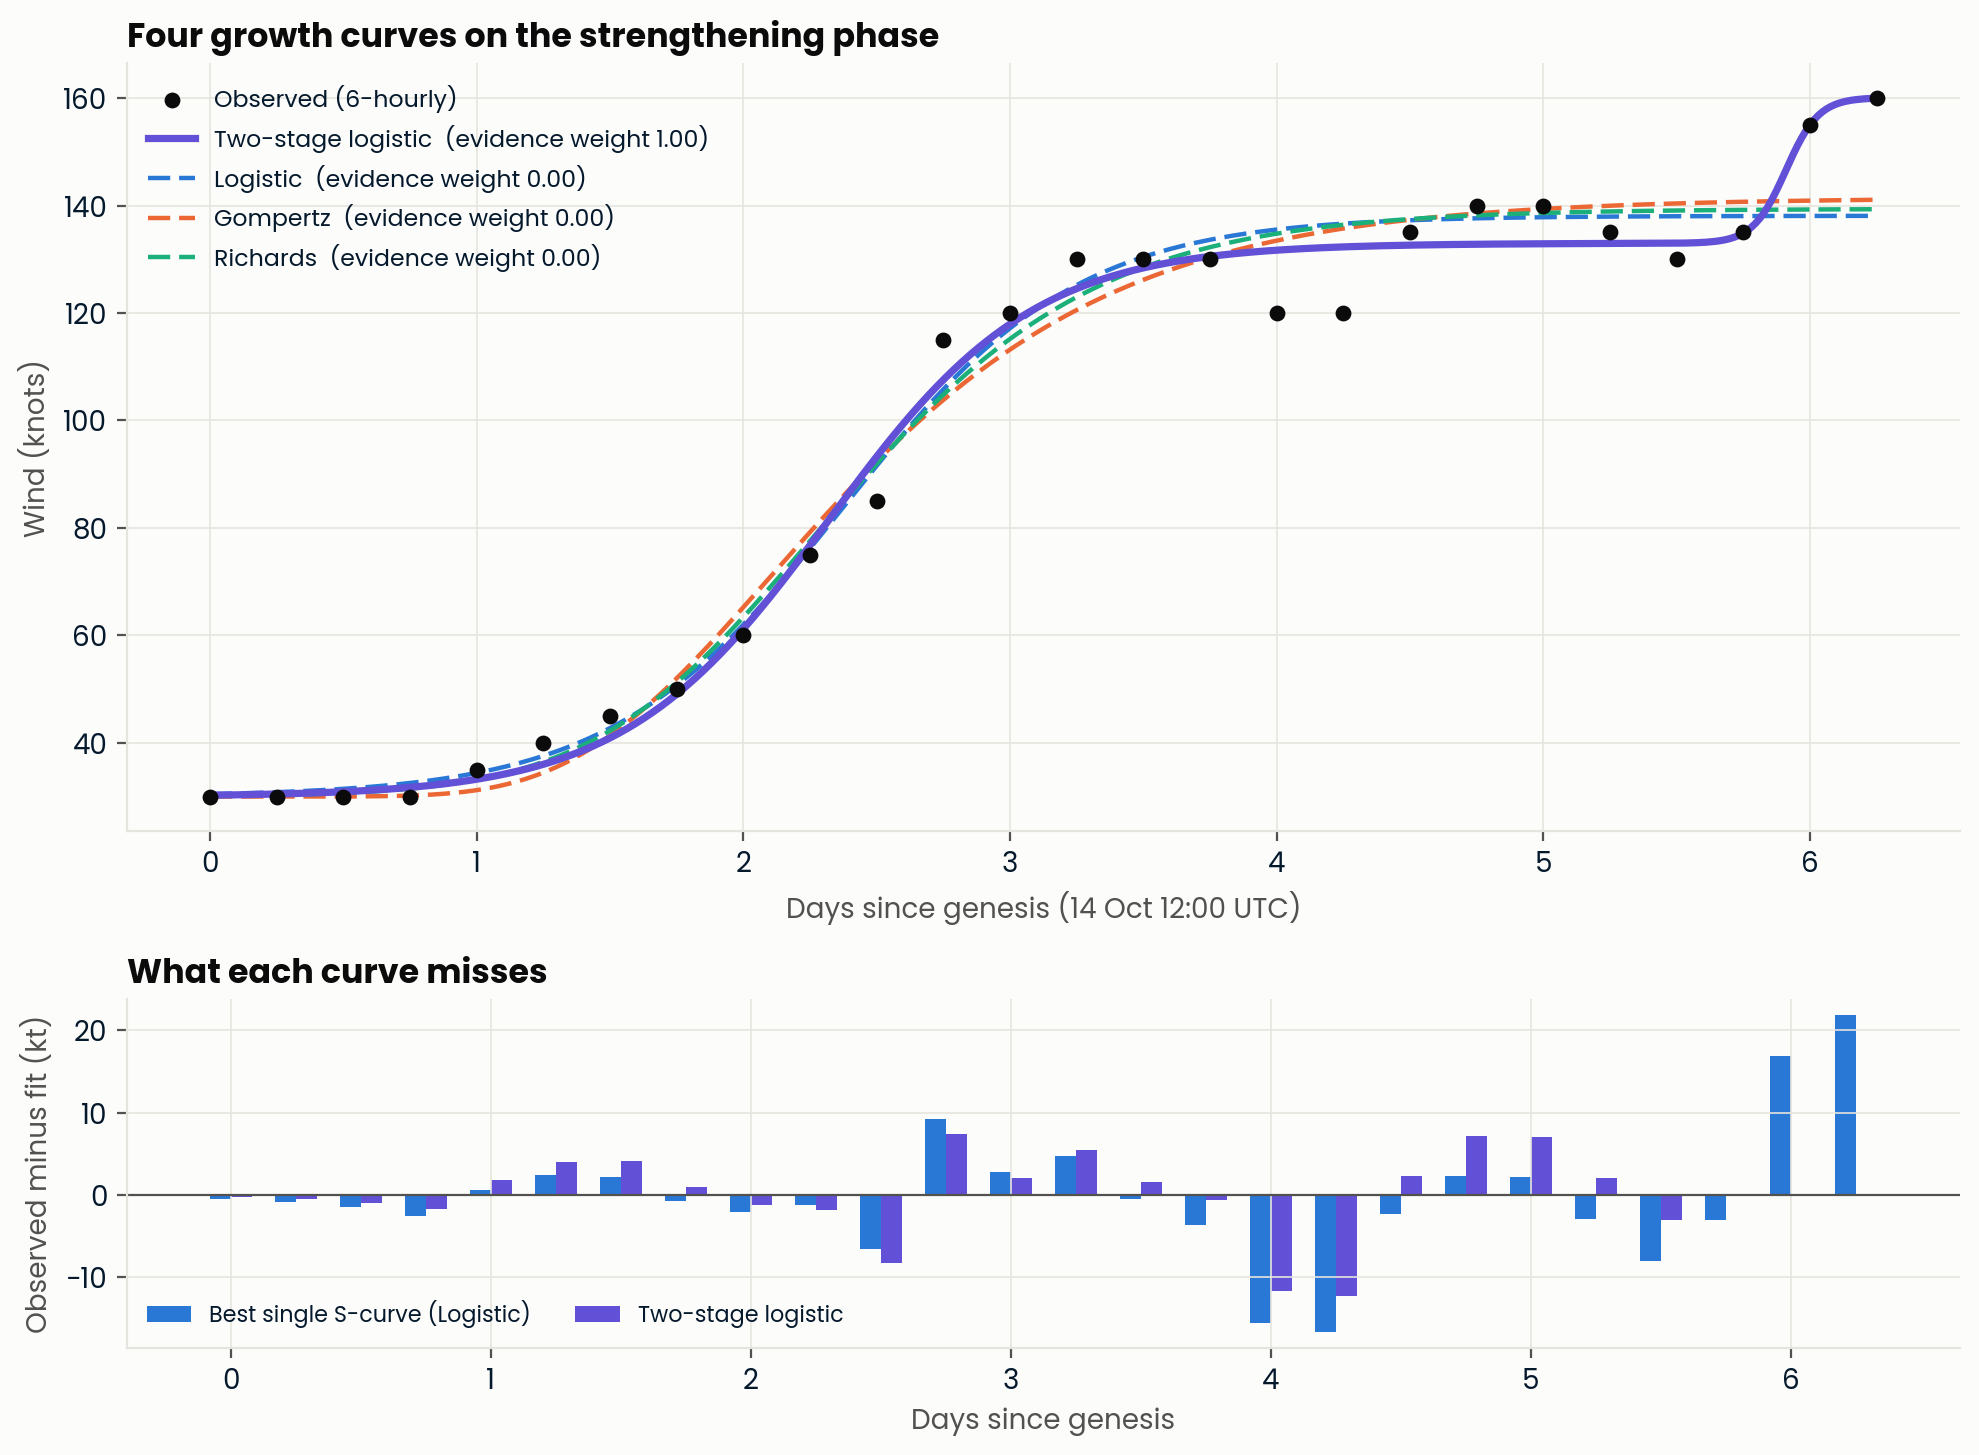

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.4), height_ratios=[2.2, 1])
cu.plot_rise_fits(track, contest, curves, rise_data, ax=ax1)
cu.plot_residuals(contest, curves, rise_data, ax=ax2)
fig.tight_layout()
fig.savefig("figures/r4_growth_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the contest.** Read the `delta_AICc` column first. The three single S-curves land within about 3 points of each other: no single shape of S is better than another, so the question "logistic or Gompertz?" has no answer for this storm. The two-stage logistic beats all of them by more than 14 points, a decisive margin even after paying for its extra parameters. Its first plateau (`first_plateau_kt`) sits near 133 knots, and the second surge (`second_surge_day`) comes almost six days after genesis, on 20 October.

The residual bars show why. Every single S-curve levels off around 138 to 142 knots, so it overshoots the three-day plateau and badly undershoots the final surge to 160 knots. The two-stage curve follows both.

**In population terms:** Champi grew like a colony on two foods. It surged until it had used up the first easy gain, paused for about three days while it reorganized, and then found a second surge to its true peak. One caution keeps this honest: the second surge rests on only the last few positions before the peak, so its timing is uncertain to within 6 to 12 hours. The neighboring residuals are also correlated (printed above), which makes AICc somewhat overconfident. The next cell tests how much the result leans on individual positions.

#### How sturdy is the two-stage result?

A result that hangs on one or two data points deserves a stress test. The cell below refits the whole contest after dropping each strengthening-phase position in turn, and after ending the window 12 hours before the peak. `lead_AICc` is how many AICc points the two-stage curve leads the best single S-curve; above 10 is decisive, 4 to 10 clear, 2 to 4 meaningful, below 0 the single curve wins.

In [9]:
robust = cu.growth_robustness(track)
robust

,check,lead_AICc,verdict
0,"All positions, genesis to peak (baseline)",14.2,decisive
1,Drop any one of the first 22 positions,11.6 to 16.2,decisive
2,Drop the 135 kt position (20 Oct 06:00 UTC),12.6,decisive
3,Drop the 155 kt position (20 Oct 12:00 UTC),7.3,clear
4,Drop the 160 kt position (20 Oct 18:00 UTC),2.6,meaningful
5,End the window 12 h before the peak,-5.5,single curve wins


**Reading the stress test.** Dropping any early or middle position barely matters: the two-stage curve stays decisively ahead. The result leans on the end of the climb. Remove the 155-knot reading and the lead is still clear; remove the 160-knot peak and it shrinks to a narrow lead; end the window 12 hours before the peak and a single S-curve wins. In plain words: the first stage and the long pause are solid, and the second stage is the 12-hour jump from 135 to 160 knots. That jump is in the official track and matches how eyewall cycles behave [21], but it is two readings from satellite estimates, so the two-stage label should be read as *the best description of this track*, not a measured law.

### R5. One curve for the whole life, and how fast it faded

To describe the full life, rise and fall together, we use a skewed bell, the same shape hydrologists use for a flood wave passing a river gauge:

$$V(t) = L + A\left(\frac{t}{t_p}\right)^{a} e^{\,a\,(1 - t/t_p)}$$

It peaks at height $L + A$ at time $t_p$; the shape number $a$ sets how sharp the peak is. We then compare two plain averages with Emanuel (2000), who found that the typical storm strengthens at about 12 m/s per day and weakens at about 8 m/s per day, so its decay runs at roughly two-thirds of its rise [6]. Because the decay average depends on where the window ends, the lower chart repeats it for every end point at least 24 hours after the peak.

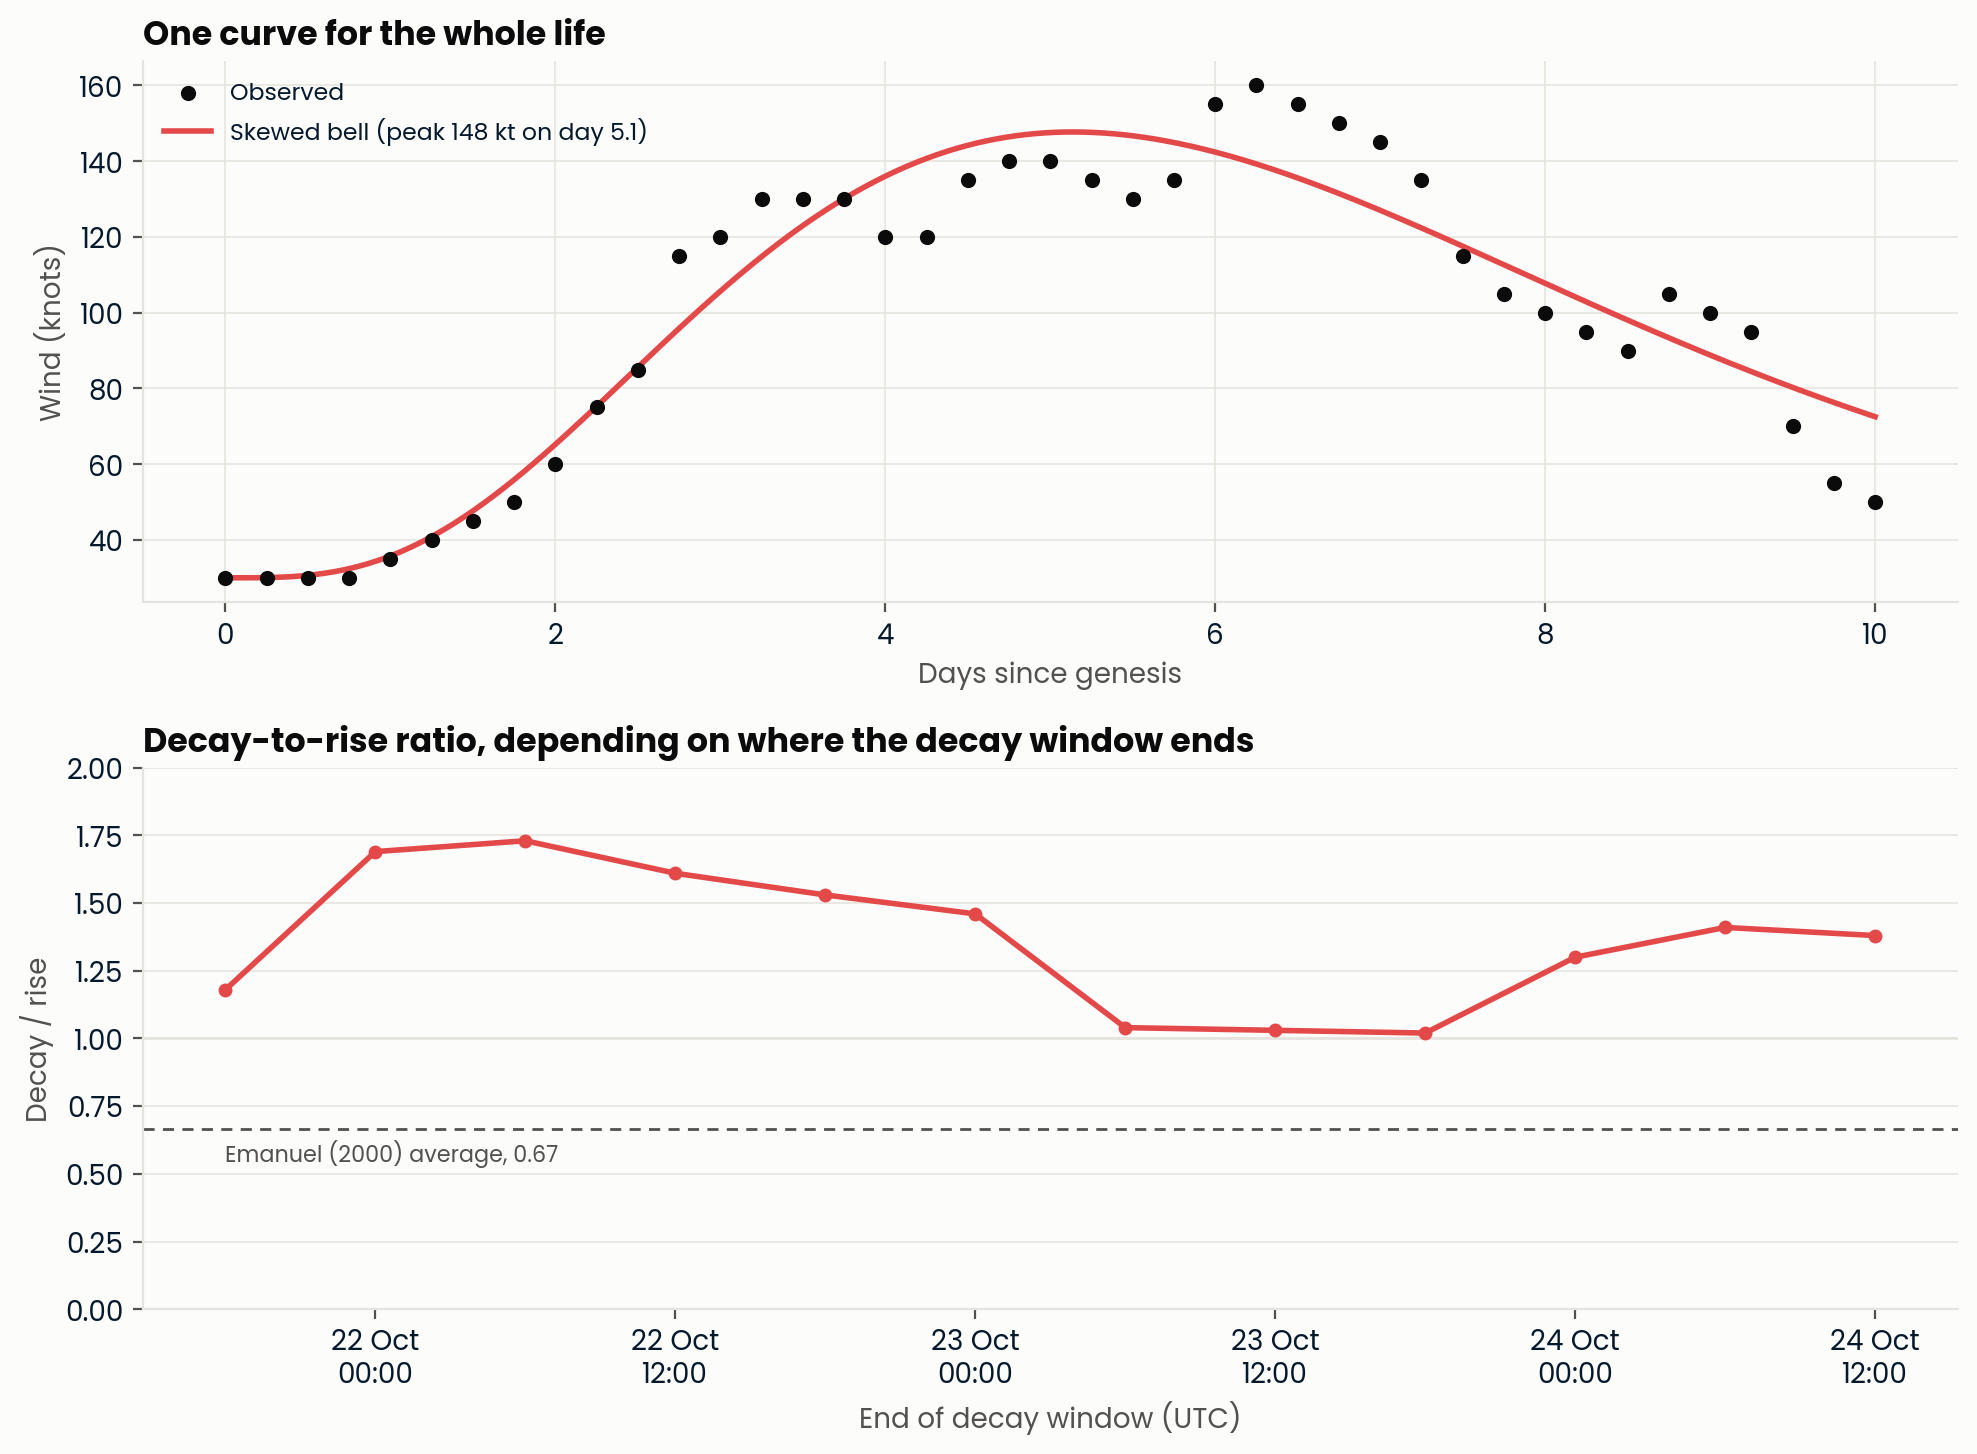

Whole-life curve: peak 147.7 kt on day 5.14, shape a = 3.63, RMSE 11.91 kt


,value
"Rise rate, typhoon strength to peak (m/s per day)",10.90
"Decay rate, peak to last position (m/s per day)",15.10
"Decay / rise (Champi, to last position)",1.38
"Decay / rise, lowest over end points",1.02
"Decay / rise, highest over end points",1.73
Decay / rise (Emanuel 2000 average),0.67
Wind lost since peak (kt),110.00
Wind at last position (kt),50.00


In [10]:
life = cu.fit_whole_life(track)
rates = cu.rise_and_decay(track)
ends = cu.decay_by_endpoint(track)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.4))
cu.plot_whole_life(track, life, ax=ax1)
cu.plot_decay_endpoints(ends, ax=ax2)
fig.tight_layout()
fig.savefig("figures/r5_whole_life.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Whole-life curve: peak {life['peak_kt']} kt on day {life['peak_day']}, shape a = {life['shape_a']}, RMSE {life['rmse_kt']} kt")
rates.to_frame("value")

**Reading the rise and fall.** The skewed bell captures the broad life of the storm but not its details: it smooths the three-day plateau and the late peak into one hump, so its peak lands too early and too low. That is the same lesson as R4 from another angle: Champi's life is not one smooth wave.

The lower chart is the more useful answer. Wherever the decay window ends, Champi's decay-to-rise ratio stays above 1, between about 1.0 and 1.7, while Emanuel's average storm sits at 0.67. So the safe statement is not a single number but a direction: Champi lost strength at least as fast as it had gained it, and usually faster. The dip in the middle of the chart is the short rebound on 23 October, just before Taiwan.

### R6. How big was Champi?

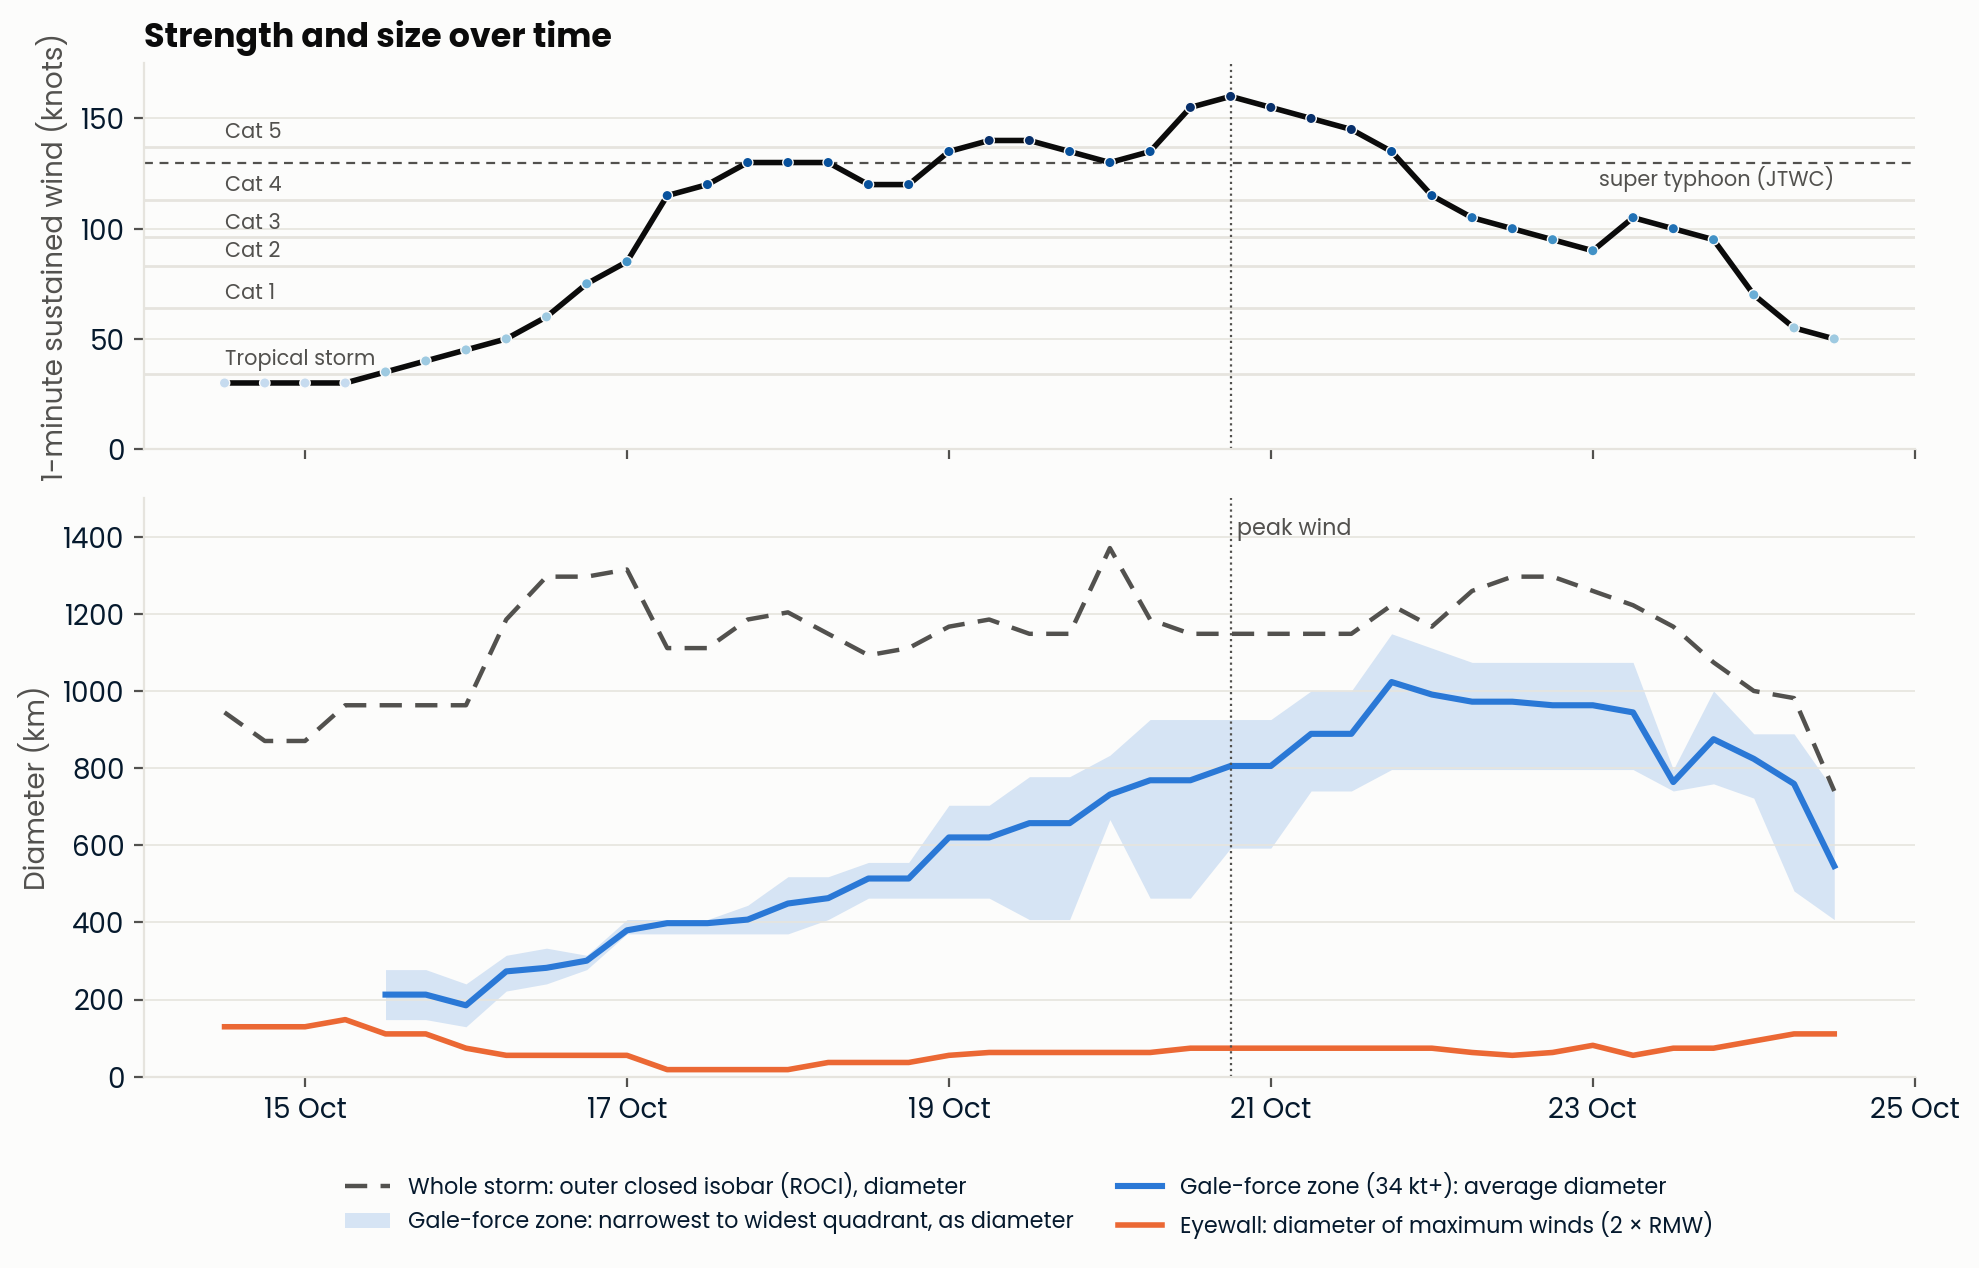

,Champi (2026)
First gale-force radius reported (UTC),2026-10-15 12:00:00
"Gale zone at first report, average diameter (km)",213
"Gale zone at peak wind, average diameter (km)",806
"Gale zone at its largest, average diameter (km)",1023
Gale zone largest at (UTC),2026-10-21 18:00:00
Wind when gale zone was largest (kt),135
Widest single gale radius (km),574
"Outer edge (ROCI) diameter, range (km)","741 to 1,370"
Eyewall radius (RMW) at first position (km),65
Tightest eyewall radius (km),9


In [11]:
if cu.has_size(track):
    sizes = cu.size_numbers(track)
    axes = cu.plot_size(track)
    axes[0].figure.tight_layout()
    axes[0].figure.savefig("figures/r6_size.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(sizes.to_frame("Champi (2026)"))
else:
    sizes = None
    print("This track file has no size columns, so this section is skipped.")

**Reading size against strength.** The two panels share one time axis, and they do not move together. Three things stand out:

- **The gale-force zone kept growing after the peak.** It roughly quadrupled from its first report on 15 October to the peak on 20 October, and was widest about a day later, near 1,000 km across, while the winds were already falling. The strongest moment was not the biggest one; storms often spread out as they weaken and move poleward.
- **The eye tightened as the storm spun up.** The radius of maximum winds shrank to about 9 km on 17 October, at the end of Champi's fastest 24-hour strengthening. A contracting eyewall during rapid intensification is a classic signature: like a skater pulling in their arms, the winds spin faster as the ring tightens.
- **The whole storm was huge throughout.** The outer edge (ROCI) spanned roughly 740 to 1,370 km in diameter; at its largest, nearly twice the length of Luzon.

The shaded band shows how lopsided the gale-force zone was: the widest quadrant often reached hundreds of kilometers farther than the narrowest.

### R7. When did gale-force winds reach Taiwan?

Taiwan has no fixed box like the Philippine Area of Responsibility. Its Central Weather Administration issues sea and land typhoon warnings when a storm's winds are expected to threaten its waters or land. Here we ask a simpler, measurable version: at each position, is the gale-force radius on the side facing Taiwan at least as long as the distance from the center to Taiwan's nearest coast?

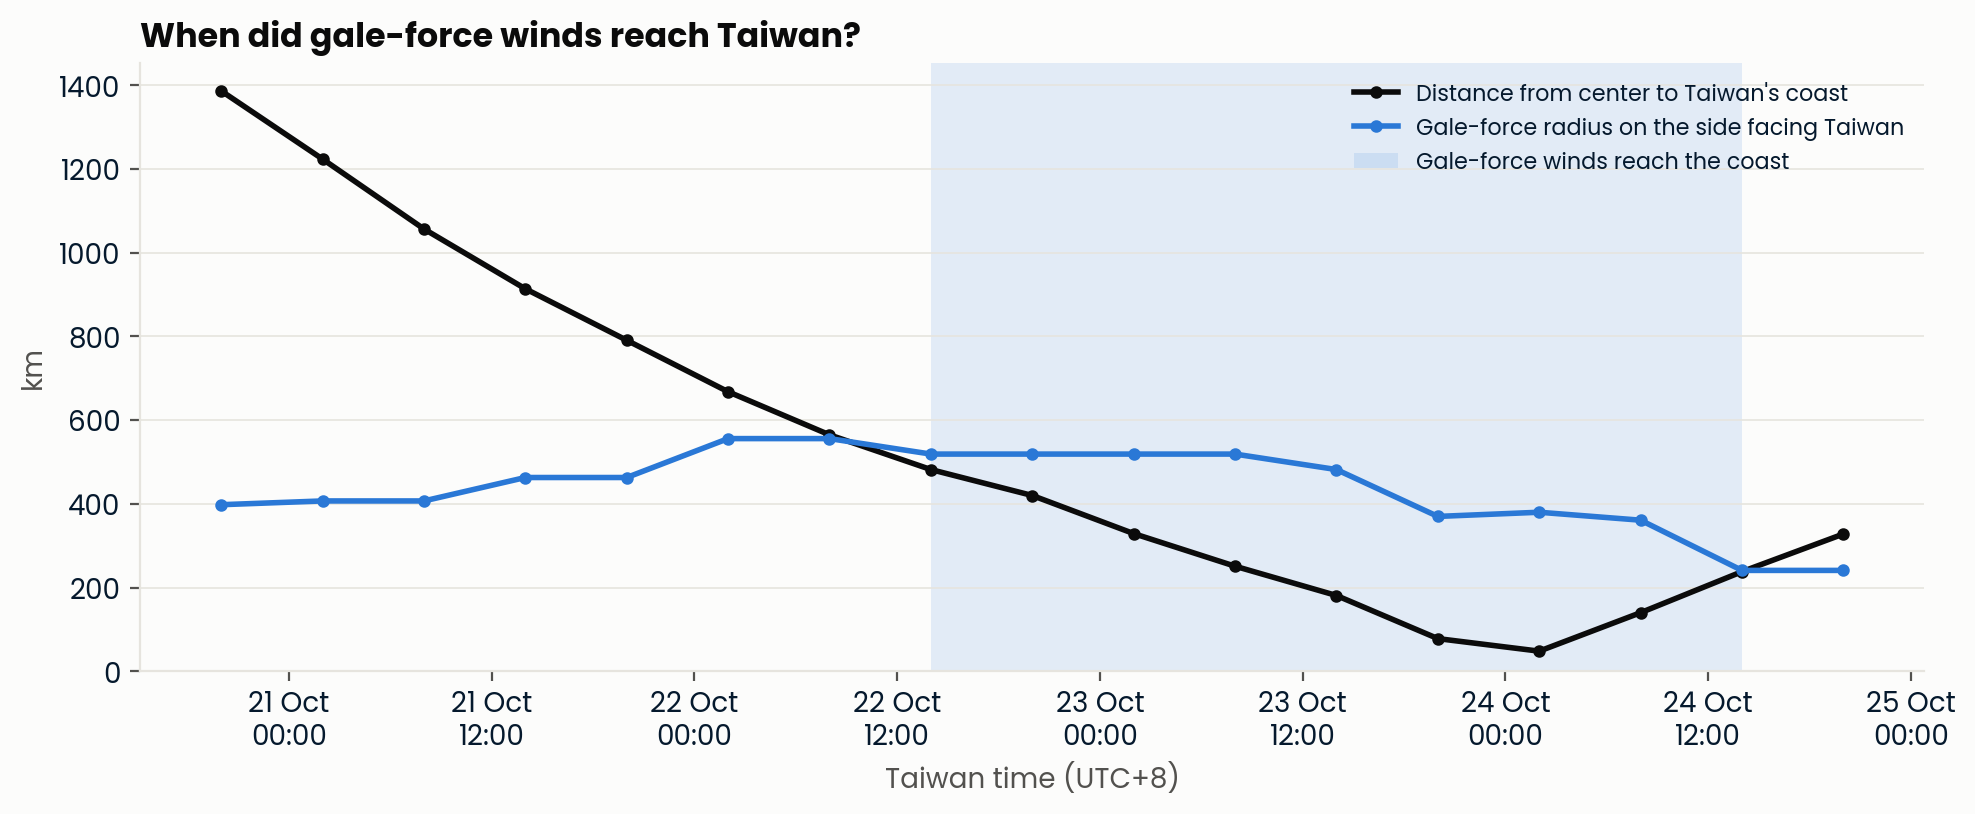

Gale-force winds reach Taiwan's coast from 22 Oct 14:00 to 24 Oct 14:00 Taiwan time (6-hourly positions); closest approach 48 km


,iso_time,taiwan_time,distance_km,bearing_to_taiwan,quadrant,gale_radius_toward_taiwan_km,gale_reaches_taiwan,wind_kt
26,2026-10-21 00:00:00,2026-10-21 08:00:00,1057,295,NW,407.0,False,155
27,2026-10-21 06:00:00,2026-10-21 14:00:00,914,294,NW,463.0,False,150
28,2026-10-21 12:00:00,2026-10-21 20:00:00,791,293,NW,463.0,False,145
29,2026-10-21 18:00:00,2026-10-22 02:00:00,668,291,NW,556.0,False,135
30,2026-10-22 00:00:00,2026-10-22 08:00:00,565,290,NW,556.0,False,115
31,2026-10-22 06:00:00,2026-10-22 14:00:00,482,299,NW,519.0,True,105
32,2026-10-22 12:00:00,2026-10-22 20:00:00,420,299,NW,519.0,True,100
33,2026-10-22 18:00:00,2026-10-23 02:00:00,329,294,NW,519.0,True,95
34,2026-10-23 00:00:00,2026-10-23 08:00:00,251,289,NW,519.0,True,90
35,2026-10-23 06:00:00,2026-10-23 14:00:00,181,291,NW,482.0,True,105


In [12]:
if cu.has_size(track):
    clock = cu.taiwan_clock(track, land)
    gale = cu.gale_window(clock)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    cu.plot_taiwan_clock(clock, ax=ax, start="2026-10-20 12:00")
    fig.tight_layout()
    fig.savefig("figures/r7_taiwan_clock.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Gale-force winds reach Taiwan's coast from {gale['first_taiwan_time']:%d %b %H:%M} "
          f"to {gale['last_taiwan_time']:%d %b %H:%M} Taiwan time (6-hourly positions); closest approach {gale['closest_km']} km")
    display(clock[clock.iso_time >= "2026-10-21"])
else:
    clock, gale = None, None

**Reading the Taiwan clock.** The black line is how far Champi's center was from Taiwan's coast; the blue line is how far its gale-force winds reached on the side facing Taiwan. Where blue is above black (the shaded stretch), gale-force winds were over the coast. By the agency's radii, that began on the afternoon of 22 October and ended on the afternoon of 24 October, Taiwan time, about two days in all. The black line bottoms out near 50 km in the early hours of 24 October, during Champi's loop off Yilan.

This lines up with Taiwan's own warnings: the land typhoon warning was issued on the morning of 22 October and expected to be lifted on the evening of 24 October [17]. A two-line chart built from the storm's own radii recovers the warning window, a useful sanity check on both.

> **Tip: why "by the agency's radii".** Wind radii are estimates over open water, made from satellite wind data and forecaster judgment, and given only per quadrant. Mountains change the winds over land. Treat the clock as a timeline of exposure, not a measurement of the wind anyone felt.

### R8. Strongest is not when it hits

The category on the news is usually the storm's *peak*. What a coast actually faces is the storm's state *when it arrives*. The map zooms in on Champi's last two days, with dashed lines at 100, 200 and 300 km from Taiwan's coast and every 6-hourly position labeled with its time (Taiwan time) and wind. Each position is drawn with the storm symbol from the animation, the same size throughout, and colored by category, darker for stronger; an open center means Champi had dropped below typhoon strength. The first position shown, the closest approach and the last position are circled in black and carry bold labels with their category. The highlighted legend lists only the five categories Champi passed through near Taiwan, strongest first, with the winds it actually had in each, so the weakening reads from top to bottom. The table compares its peak with its strongest moment near Taiwan and its closest approach.

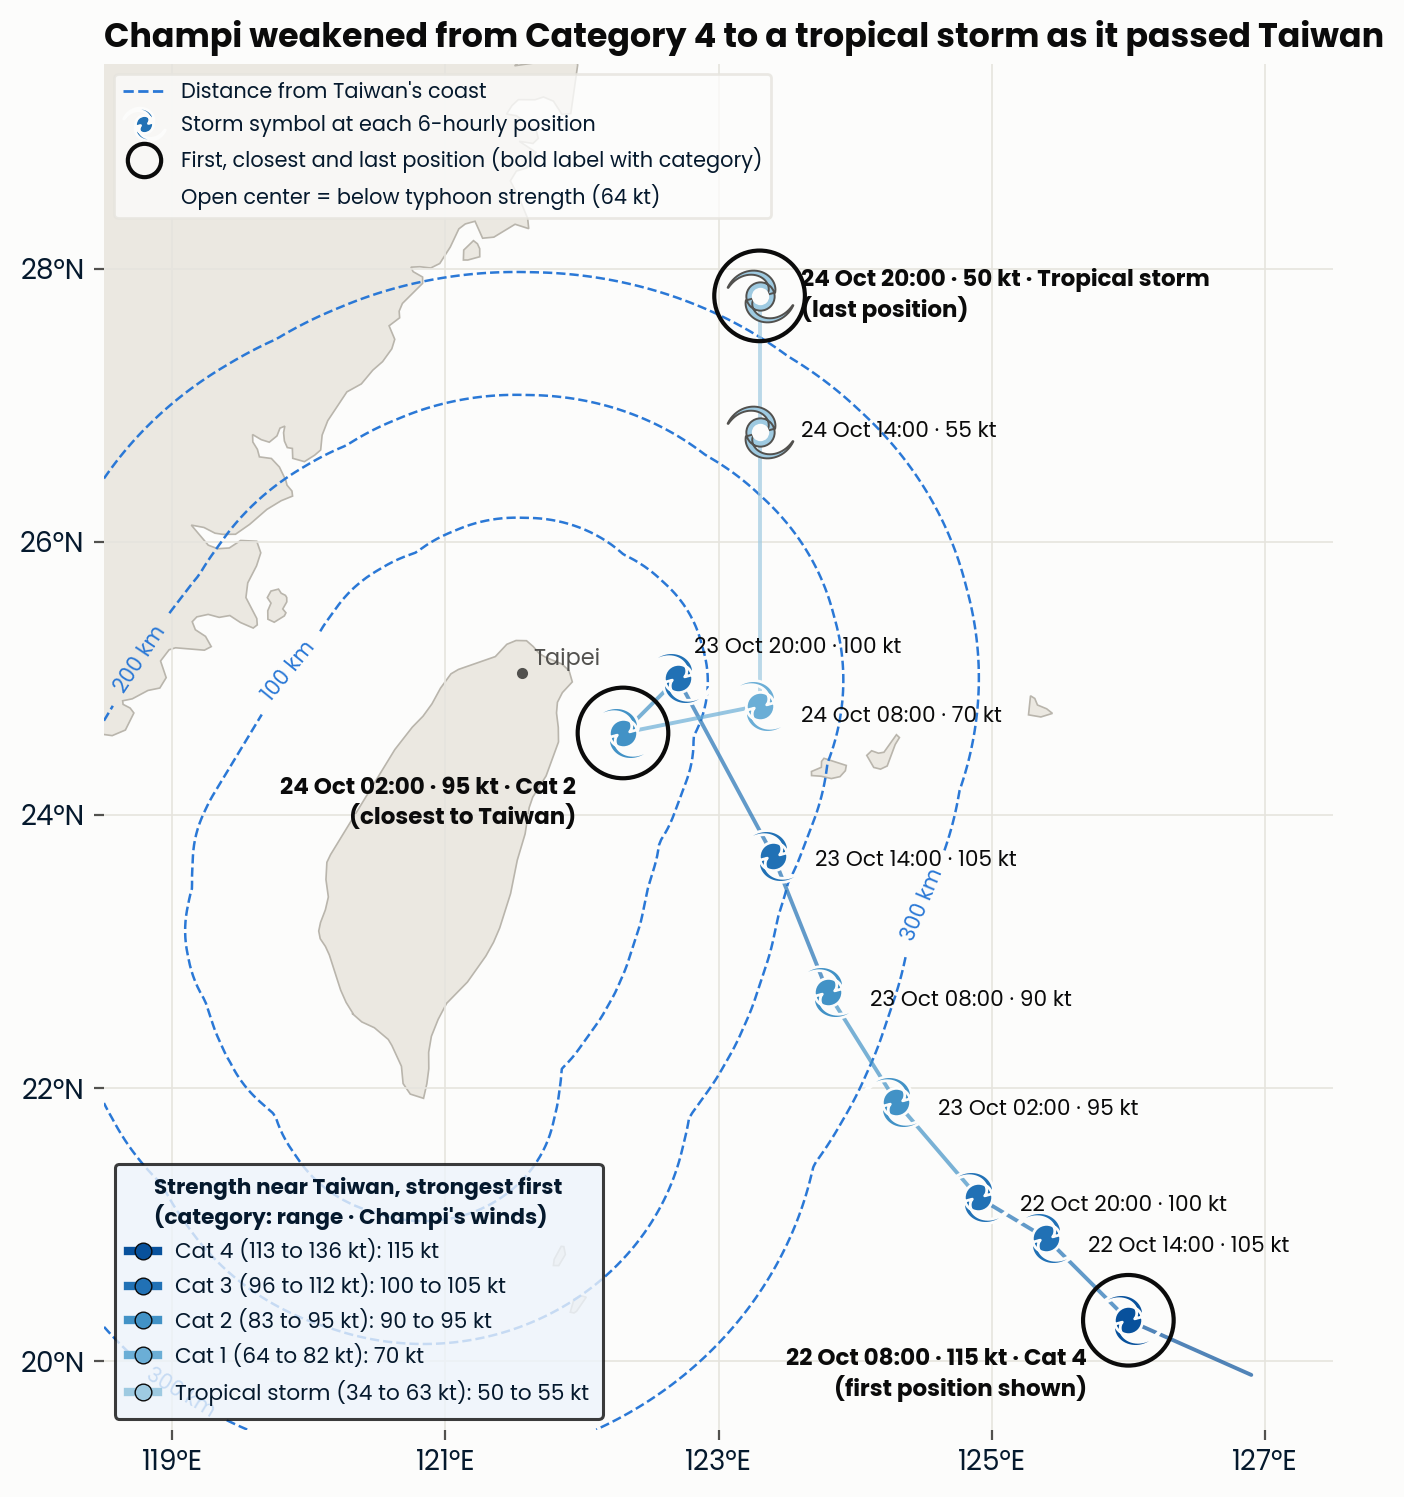

,time_utc,taiwan_time,wind_kt,category,pressure_hpa,distance_km
Peak (anywhere),2026-10-20 18:00:00,2026-10-21 02:00:00,160,Cat 5,895,1224
Strongest within 300 km of Taiwan,2026-10-23 06:00:00,2026-10-23 14:00:00,105,Cat 3,949,181
Closest to Taiwan,2026-10-23 18:00:00,2026-10-24 02:00:00,95,Cat 2,951,48


In [13]:
if cu.has_size(track):
    near = cu.near_taiwan_numbers(track, clock, within_km=300)
    fig, ax = plt.subplots(figsize=(7.5, 7.6))
    cu.plot_taiwan_zoom(track, clock, land, ax=ax, marker="symbol",
                        title="Champi weakened from Category 4 to a tropical storm as it passed Taiwan")
    fig.tight_layout()
    fig.savefig("figures/r8_near_taiwan.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(near)
else:
    near = None

**Reading the map.** Champi came at Taiwan from the southeast, slowed and looped just off the Yilan coast in northeast Taiwan, then turned north. At its closest, around 02:00 on 24 October Taiwan time, its center was about 48 km off the coast with winds of 95 knots, a Category 2 storm. The strongest it ever got within 300 km of Taiwan was 105 knots (Category 3), on the afternoon of 23 October, still about 180 km out. Its peak of 160 knots (Category 5) had come three days earlier, more than 1,200 km away over the open Philippine Sea. The closer Champi got to Taiwan, the weaker it was.

So why was Taiwan battered by a storm past its prime? A category describes only the most violent ring of wind around the eye, a few tens of kilometers wide. What a coast experiences also depends on how big the storm is, how long it lingers and what it runs into. Near Taiwan, Champi was still huge (its gale-force zone close to 900 km across, R6), it lingered (R7 puts gale-force winds on the coast for about two days), and it pressed against the island's mountains, which squeeze extra rain out of moist air and speed up gusts through gaps and over ridges. Yilan took more than 400 mm of rain in a day [20], and waves swept away the one person who died [16].

> **Tip: watch the arrival, not the peak.** When a storm enters PAR or makes headlines as a "super typhoon", ask two questions: how strong will it be *when it reaches me*, and how big and slow will it be then? The answers can differ a lot from the peak. The winds here are the agency's estimates of the storm's strongest wind near its center, not winds measured on Taiwan; gusts over mountains can run higher.

In [14]:
from pathlib import Path
import json

Path("results").mkdir(exist_ok=True)
track.to_csv("results/champi_track_used.csv", index=False)
contest.to_csv("results/growth_curve_contest.csv", index=False)
ends.to_csv("results/decay_by_endpoint.csv", index=False)
summary = {
    "data_source": str(track["source"].iloc[0]),
    "runway": {k: str(v) for k, v in runway.items()},
    "best_growth_law": contest["model"].iloc[0],
    "growth_curve_contest": contest.to_dict(orient="records"),
    "residual_lag1": {m: round(cu.residual_lag1(curves, rise_data, m), 2) for m in contest["model"]},
    "growth_robustness": robust.astype(str).to_dict(orient="records"),
    "whole_life_curve": {k: float(v) for k, v in life.items() if k != "curve"},
    "rise_and_decay": {k: float(v) for k, v in rates.items()},
}
if sizes is not None:
    clock.to_csv("results/taiwan_clock.csv", index=False)
    summary["size"] = {k: str(v) for k, v in sizes.items()}
    summary["gale_reaches_taiwan"] = {k: str(v) for k, v in gale.items()} if gale else None
    summary["peak_vs_near_taiwan"] = {m: {k: str(v) for k, v in row.items()} for m, row in near.iterrows()}
    summary["par_window"] = {k: str(v) for k, v in cu.par_window(track).items()}
Path("results/summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved results/ (track, contest, decay by end point, Taiwan clock, summary.json)")

Saved results/ (track, contest, decay by end point, Taiwan clock, summary.json)


## Discussion

The operational logistic model treats a storm's intensity as one climb toward one ceiling [3], [4]. For Champi, that picture is half right. The climb out of the depression stage is a clean S, and any of the three classic S-curves describes it equally well; the data cannot tell a symmetric S from a lopsided one. What the single curves cannot do is the second act. Champi stalled near 133 knots for three days and then surged again to 160. A two-stage curve, the same one biologists use for bacteria switching foods [12], captures both acts and wins the contest decisively with all the data. The robustness check is the fair print: the win leans on the last 12 hours before the peak, and with the final 160-knot reading removed the two-stage lead shrinks to a narrow one.

Physically, the pause is not mysterious. Intense typhoons often go through eyewall replacement cycles, in which a new eyewall forms outside the old one, the storm stalls or weakens while the inner one collapses, and then it strengthens again once the new eyewall contracts. Aircraft studies of Atlantic hurricanes describe exactly this sequence of intensification, weakening and reintensification, and the reintensification often carries the storm to its lifetime peak [21]. The growth-curve view does not prove that happened in Champi, but it gives the pause a precise shape and timing to compare with microwave satellite imagery.

Size tells a second story that strength alone hides. Champi's eye tightened to about 9 km during its fastest strengthening, then its gale-force zone kept spreading for a day after the peak, to about 1,000 km across. For people on the ground, the second fact matters more: a weakening but spreading storm can expose more coastline to damaging winds than the same storm at its peak. On the way down, Champi lost strength at least as fast as it had gained it, faster than Emanuel's average storm [6], with the steepest losses as it stalled and looped off northeast Taiwan.

The near-Taiwan map (R8) adds the lesson that matters most for people on the coast. Champi peaked far out at sea and reached Taiwan three categories weaker, never above Category 3 within 300 km of the coast, yet large and slow. Super Typhoon Haiyan (Yolanda) in 2013 was the opposite case. The Joint Typhoon Warning Center estimated 170-knot one-minute winds when it first came ashore in Eastern Samar [19], it struck Leyte at near peak strength and moving fast, and Leyte Gulf funneled its storm surge to about 7 m at Tacloban [18]. The government count was 6,300 dead and more than 1,000 missing [19]. Same basin, same kind of storm, opposite timing: Haiyan arrived at its strongest and its surge did the killing; Champi arrived past its peak and did its damage through size, time and terrain. A storm's peak and its arrival are different numbers, and warnings are about the second.

What none of this explains is *why* Champi had so much room to grow. A storm born near the Philippines does not have five thousand kilometers of warm ocean ahead of it. That is the question for Part 2.

## Known Limitations

- **One storm.** Every fit here describes Champi only. Nothing is claimed about typhoons in general.
- **Provisional track.** This is JTWC's working best track; agencies revise best tracks for months. The `source` column records which version was used, and the numbers will be rerun on the final track.
- **Start point.** The analysis starts at the official genesis (14 Oct 12:00 UTC). Starting three days earlier, with the pre-genesis disturbance, changes which single S-curve looks best, though not the two-stage result.
- **Few points, correlated errors.** Twenty-six six-hourly positions cover the strengthening phase, and neighboring residuals are correlated, so AICc is somewhat overconfident. The two-stage margin is large enough to survive this; the ranking among single S-curves is not.
- **The second surge is short.** It rests on the last few positions before the peak (135 to 155 to 160 knots in 12 hours). With all data the two-stage lead is decisive; drop the 160-knot reading and it falls to a narrow lead; end the window 12 hours earlier and a single S-curve wins. Satellite-based peak winds carry roughly 10 knots of uncertainty, so the result is only as solid as that final jump.
- **Wind is estimated, not measured.** Western Pacific intensities come mostly from satellite estimates without aircraft reconnaissance, so peak winds carry an uncertainty of roughly 10 knots or more.
- **Radii are coarse.** Wind radii are estimates over open water, rounded and given per quadrant. Gale-force reach over Taiwan is a timeline of exposure, not a wind measurement.
- **Rise and decay windows.** The averages depend on where each window starts and stops, which is why R5 shows every end point.

## Future Work

**Part 2 (November): The Split.** Was Champi's long runway luck, or El Niño? We line up every western Pacific typhoon since 1980, split them into El Niño and La Niña years, and see where Champi falls on each yardstick: where storms are born, how far they travel, how long they live, and how big they get.

**Part 3 (December): Champi's Twins.** Which past storms is Champi actually like? A network of storms linked by similar tracks, with Champi's closest matches chosen by a rule written down before the analysis.

A natural follow-up to this notebook: does two-stage growth show up in other super typhoons, and does the pause line up with eyewall replacement cycles seen in microwave satellite imagery?

## References

[1] S. J. Camargo and A. H. Sobel, "Western North Pacific tropical cyclone intensity and ENSO," *J. Climate*, vol. 18, no. 15, pp. 2996–3006, 2005.

[2] I. L. Corporal-Lodangco, L. M. Leslie, and P. J. Lamb, "Impacts of ENSO on Philippine tropical cyclone activity," *J. Climate*, vol. 29, no. 5, pp. 1877–1897, 2016, doi: 10.1175/JCLI-D-14-00723.1.

[3] M. DeMaria, "A simplified dynamical system for tropical cyclone intensity prediction," *Mon. Wea. Rev.*, vol. 137, no. 1, pp. 68–82, 2009.

[4] Y. Zhou, J. Zhao, R. Zhan, P. Chen, Z. Wu, and L. Wang, "A logistic-growth-equation-based intensity prediction scheme for western North Pacific tropical cyclones," *Adv. Atmos. Sci.*, vol. 38, pp. 1750–1762, 2021, doi: 10.1007/s00376-021-0435-1.

[5] K. P. Burnham and D. R. Anderson, *Model Selection and Multimodel Inference: A Practical Information-Theoretic Approach*, 2nd ed. New York, NY, USA: Springer, 2002, doi: 10.1007/b97636.

[6] K. A. Emanuel, "A statistical analysis of tropical cyclone intensity," *Mon. Wea. Rev.*, vol. 128, no. 4, pp. 1139–1152, 2000.

[7] K. R. Knapp, M. C. Kruk, D. H. Levinson, H. J. Diamond, and C. J. Neumann, "The International Best Track Archive for Climate Stewardship (IBTrACS): Unifying tropical cyclone best track data," *Bull. Amer. Meteor. Soc.*, vol. 91, pp. 363–376, 2010, doi: 10.1175/2009BAMS2755.1. Dataset: IBTrACS v04r01, NOAA NCEI, doi: 10.25921/82ty-9e16.

[8] Natural Earth, "1:50m Physical Vectors: Land," naturalearthdata.com, public domain.

[9] J. Kaplan and M. DeMaria, "Large-scale characteristics of rapidly intensifying tropical cyclones in the North Atlantic basin," *Wea. Forecasting*, vol. 18, pp. 1093–1108, 2003.

[10] B. Gompertz, "On the nature of the function expressive of the law of human mortality, and on a new mode of determining the value of life contingencies," *Phil. Trans. R. Soc. Lond.*, vol. 115, pp. 513–583, 1825, doi: 10.1098/rstl.1825.0026.

[11] F. J. Richards, "A flexible growth function for empirical use," *J. Exp. Bot.*, vol. 10, no. 2, pp. 290–300, 1959, doi: 10.1093/jxb/10.2.290.

[12] J. Monod, "The growth of bacterial cultures," *Annu. Rev. Microbiol.*, vol. 3, pp. 371–394, 1949, doi: 10.1146/annurev.mi.03.100149.002103.

[13] P. S. Meyer, "Bi-logistic growth," *Technol. Forecast. Soc. Change*, vol. 47, no. 1, pp. 89–102, 1994.

[14] Joint Typhoon Warning Center, working best track (ATCF b-deck) for tropical cyclone 29W (Champi), 2026, via the UCAR RAL tropical cyclone data repository. [Online]. Available: https://hurricanes.ral.ucar.edu/repository/data/bdecks_open/2026/bwp292026.dat

[15] PAGASA, "Philippine Area of Responsibility." [Online]. Available: https://www.pagasa.dost.gov.ph/learning-tools/philippine-area-of-responsibility

[16] "Typhoon Champi sweeps past Taiwan, leaving 1 dead, 527 injured," *anewz*, Oct. 2026. [Online]. Available: https://anewz.tv/world/world-news/25808/typhoon-champi-batters-taiwan-flights-cancelled/news

[17] "Land warning for Typhoon Champi expected to be lifted Saturday evening: CWA," *Focus Taiwan*, Oct. 24, 2026. [Online]. Available: https://focustaiwan.tw/society/202610240004

[18] H. Takagi, M. De Leon, M. Esteban, T. Mikami, and R. Nakamura, "Storm surge due to 2013 Typhoon Yolanda (Haiyan) in Leyte Gulf, the Philippines," in *Handbook of Coastal Disaster Mitigation for Engineers and Planners*. Elsevier, 2015, pp. 133–144, doi: 10.1016/B978-0-12-801060-0.00008-3.

[19] NOAA Climate.gov, "2013 State of the Climate: Record-breaking Super Typhoon Haiyan." [Online]. Available: https://www.climate.gov/news-features/understanding-climate/2013-state-climate-record-breaking-super-typhoon-haiyan

[20] "Typhoon Champi hits Taiwan, killing one and injuring hundreds," *Al Jazeera*, Oct. 23, 2026. [Online]. Available: https://www.aljazeera.com/news/2026/10/23/typhoon-champi-hits-taiwan-killing-one-and-injuring-350

[21] M. Sitkowski, J. P. Kossin, and C. M. Rozoff, "Intensity and structure changes during hurricane eyewall replacement cycles," *Mon. Wea. Rev.*, vol. 139, no. 12, pp. 3829–3847, 2011, doi: 10.1175/MWR-D-11-00034.1.

## Glossary

- **Maximum sustained wind:** the fastest wind near a storm's center, averaged over one minute (U.S. practice) or ten minutes (Japan, PAGASA and most other agencies). This notebook uses one-minute winds.
- **Knot (kt):** one nautical mile per hour, 1.852 km/h. A nautical mile is 1.852 km.
- **Category:** a band of wind speed. Tropical storm 34 to 63 kt, Category 1 from 64 kt up to Category 5 at 137 kt and above.
- **Super typhoon:** the U.S. Joint Typhoon Warning Center's label for a typhoon with one-minute winds of 130 kt or more.
- **Rapid intensification:** a gain of at least 30 kt in 24 hours.
- **6-hourly position:** one entry in a storm's track: where its center was, how strong and how big it was, at 00, 06, 12 and 18 UTC. Forecasters call it a *fix*.
- **Genesis:** the time a storm is first classified as a tropical depression; here, 14 October 12:00 UTC.
- **Best track:** the official, after-the-fact record of a storm's position, strength and size. A *working* best track (b-deck) is the agency's running version, updated during and just after the storm.
- **IBTrACS:** a public archive that merges best tracks from all agencies into one dataset.
- **ROCI:** radius of the outermost closed isobar, roughly the edge of the whole storm.
- **R34 (gale-force radius):** how far winds of 34 kt or more reach from the center, given for each quadrant.
- **RMW:** radius of maximum winds, roughly the eyewall.
- **Eyewall replacement cycle:** a new eyewall forms around the old one; the storm often pauses or weakens, then strengthens again as the new eyewall contracts.
- **Growth curve:** a formula for something that grows toward a limit, such as a population or a tumor.
- **Diauxic growth:** growth in two spurts with a pause between, first seen in bacteria fed two sugars.
- **AICc:** a model score that rewards fit and penalizes extra parameters; lower is better.
- **Akaike weight:** an AICc difference turned into a share of evidence across the models compared.
- **Philippine Area of Responsibility (PAR):** the box of ocean in which PAGASA monitors storms and issues bulletins.
- **El Niño:** a periodic warming of the central and eastern tropical Pacific that shifts where typhoons form.

## Graphical Abstract

The cell below builds the one-page summary used in the README and saves it to `figures/graphical_abstract.png`.

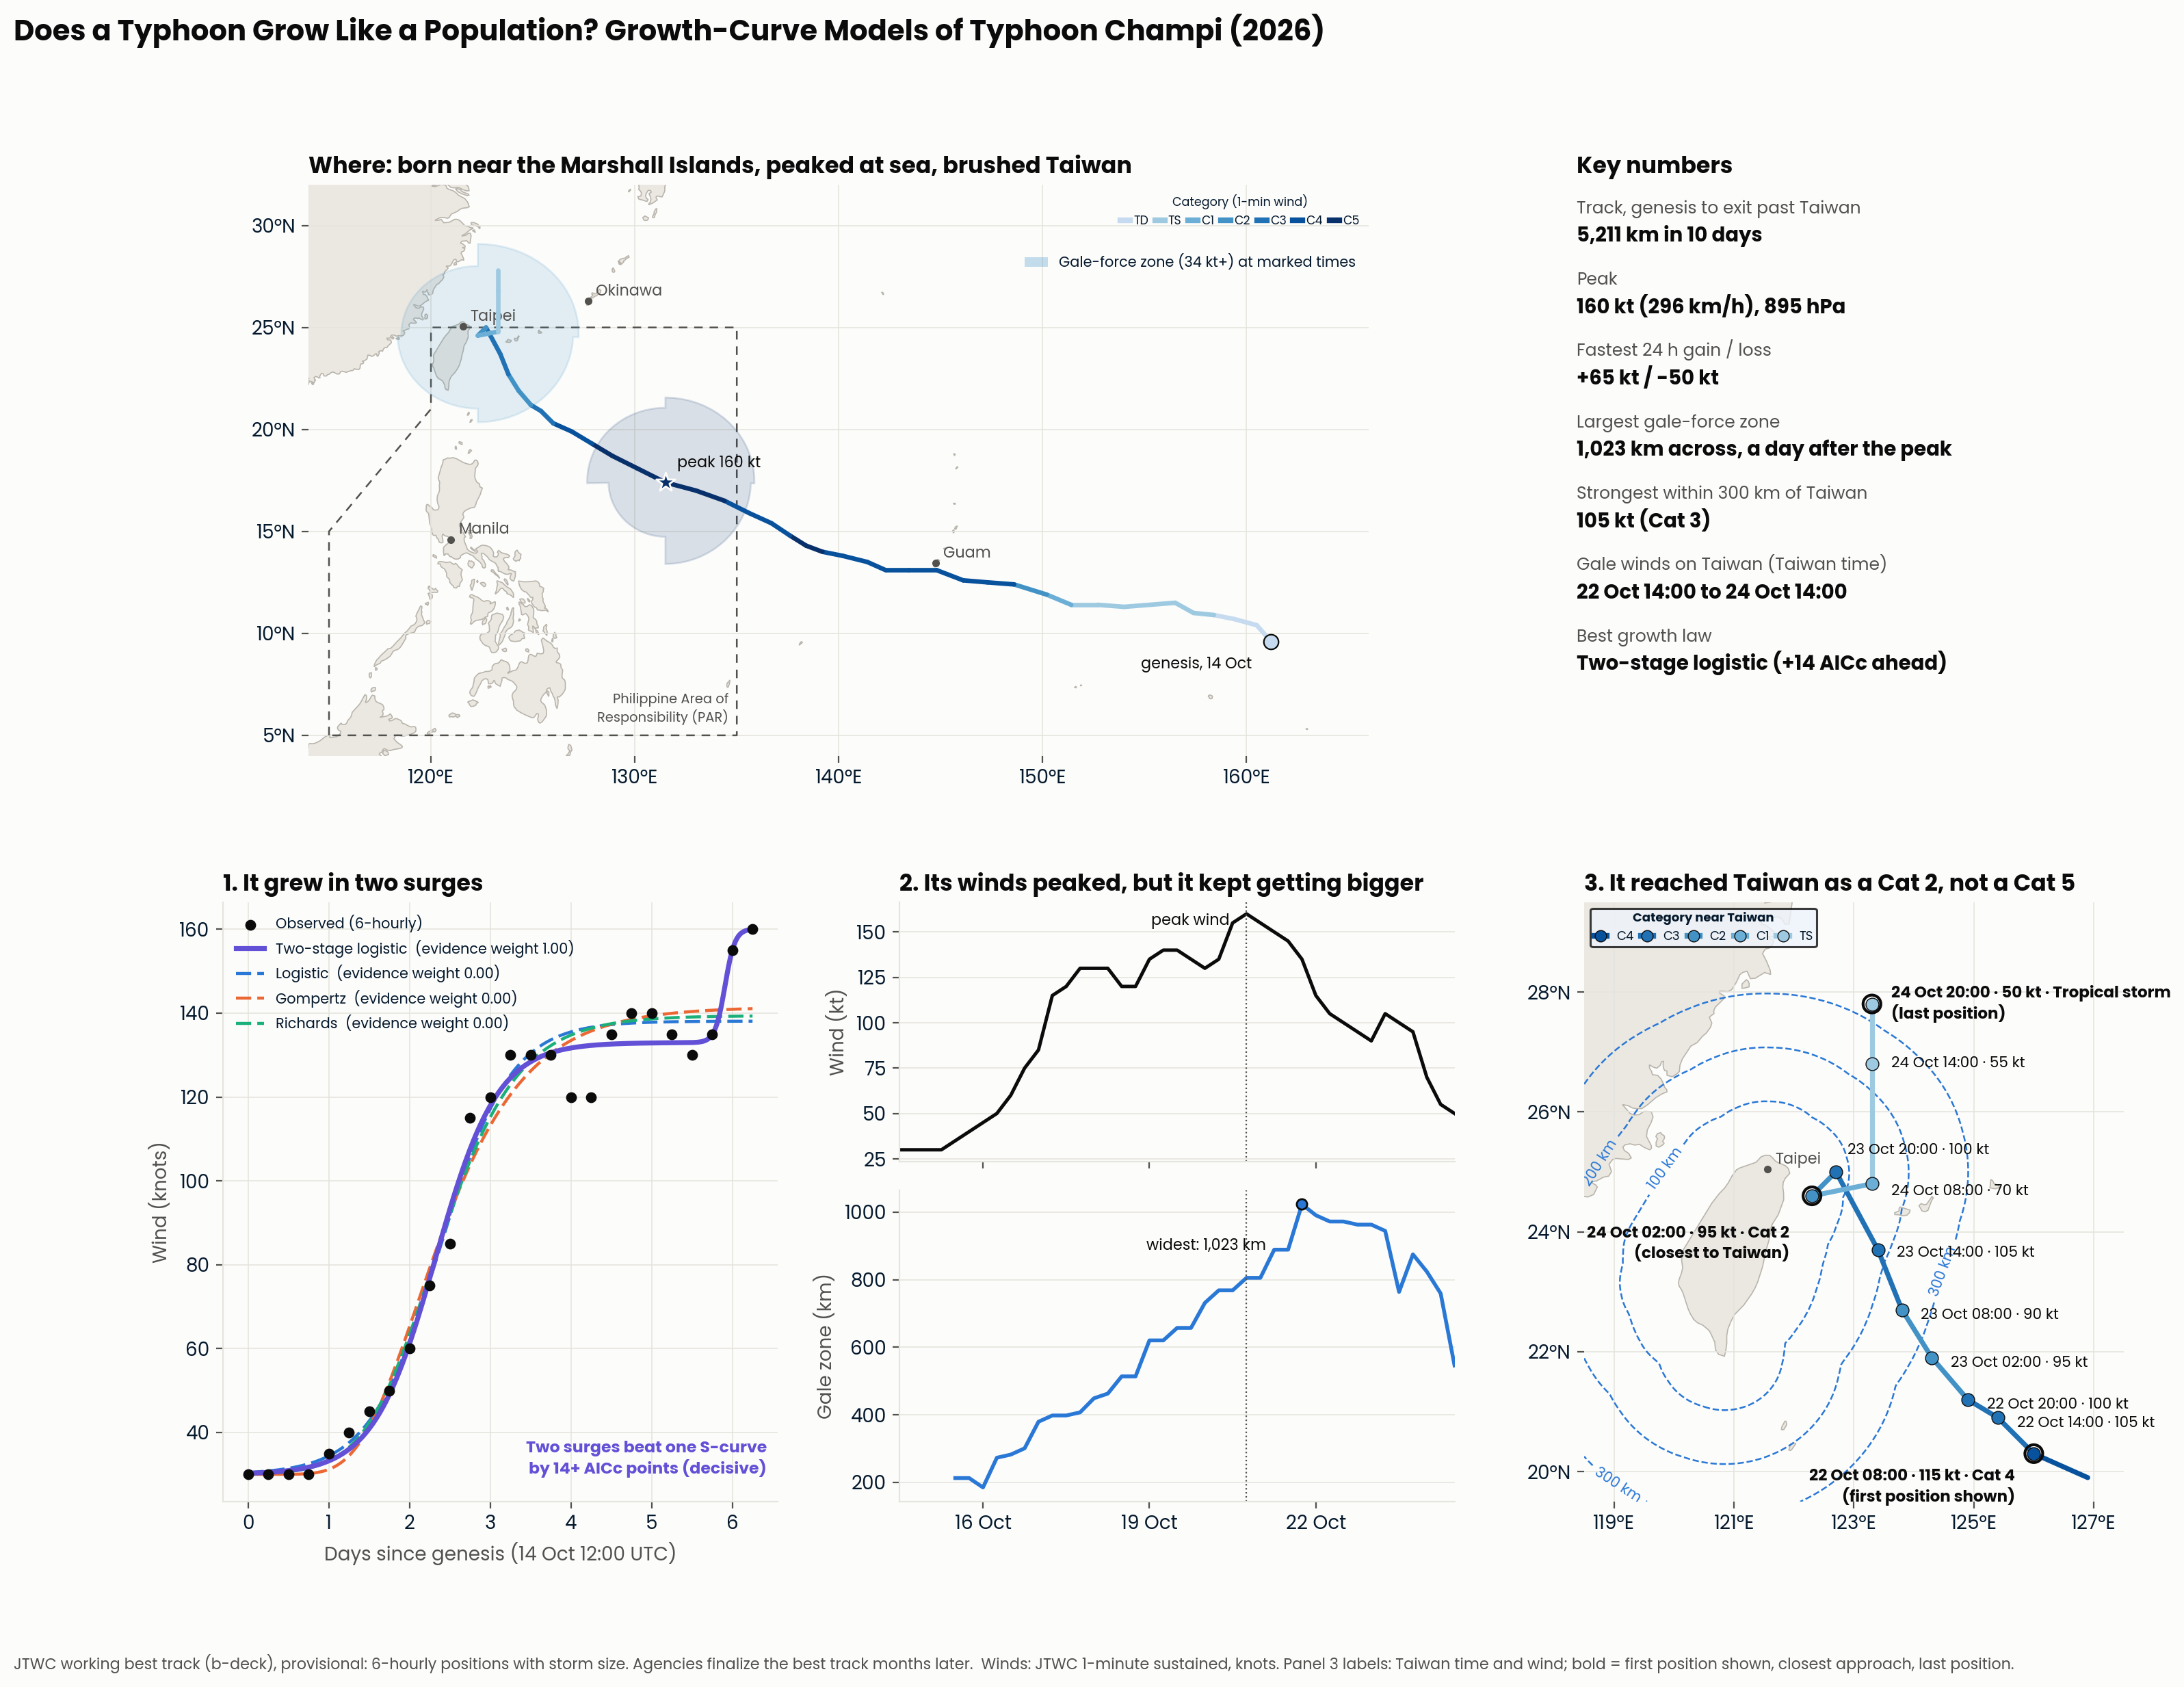

In [15]:
cu.graphical_abstract(track, land, contest, curves, rise_data, runway, rates, sizes=sizes, gale=gale,
                      path="figures/graphical_abstract.png")
plt.show()